In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import re
from bs4 import BeautifulSoup

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('train.csv')

In [3]:
df.head()
print(df.shape)

(404290, 6)


In [4]:
new_df = df.sample(50000,random_state=2)

In [5]:
new_df.head(2)

,id,qid1,qid2,question1,question2,is_duplicate
398782,398782,496695,532029,What is the best marketing automation tool for...,What is the best marketing automation tool for...,1
115086,115086,187729,187730,I am poor but I want to invest. What should I do?,I am quite poor and I want to be very rich. Wh...,0


In [6]:
def preprocess(q):
    


    
    # Replace certain special characters with their string equivalents
    q = q.replace('%', ' percent')
    q = q.replace('$', ' dollar ')
    q = q.replace('₹', ' rupee ')
    q = q.replace('€', ' euro ')
    q = q.replace('@', ' at ')
    
    # The pattern '[math]' appears around 900 times in the whole dataset.
    q = q.replace('[math]', '')
    

    
    # Decontracting words
    # https://en.wikipedia.org/wiki/Wikipedia%3aList_of_English_contractions
    # https://stackoverflow.com/a/19794953
    contractions = { 
    "ain't": "am not",
    "aren't": "are not",
    "can't": "can not",
    "can't've": "can not have",
    "'cause": "because",
    "could've": "could have",
    "couldn't": "could not",
    "couldn't've": "could not have",
    "didn't": "did not",
    "doesn't": "does not",
    "don't": "do not",
    "hadn't": "had not",
    "hadn't've": "had not have",
    "hasn't": "has not",
    "haven't": "have not",
    "he'd": "he would",
    "he'd've": "he would have",
    "he'll": "he will",
    "he'll've": "he will have",
    "he's": "he is",
    "how'd": "how did",
    "how'd'y": "how do you",
    "how'll": "how will",
    "how's": "how is",
    "i'd": "i would",
    "i'd've": "i would have",
    "i'll": "i will",
    "i'll've": "i will have",
    "i'm": "i am",
    "i've": "i have",
    "isn't": "is not",
    "it'd": "it would",
    "it'd've": "it would have",
    "it'll": "it will",
    "it'll've": "it will have",
    "it's": "it is",
    "let's": "let us",
    "ma'am": "madam",
    "mayn't": "may not",
    "might've": "might have",
    "mightn't": "might not",
    "mightn't've": "might not have",
    "must've": "must have",
    "mustn't": "must not",
    "mustn't've": "must not have",
    "needn't": "need not",
    "needn't've": "need not have",
    "o'clock": "of the clock",
    "oughtn't": "ought not",
    "oughtn't've": "ought not have",
    "shan't": "shall not",
    "sha'n't": "shall not",
    "shan't've": "shall not have",
    "she'd": "she would",
    "she'd've": "she would have",
    "she'll": "she will",
    "she'll've": "she will have",
    "she's": "she is",
    "should've": "should have",
    "shouldn't": "should not",
    "shouldn't've": "should not have",
    "so've": "so have",
    "so's": "so as",
    "that'd": "that would",
    "that'd've": "that would have",
    "that's": "that is",
    "there'd": "there would",
    "there'd've": "there would have",
    "there's": "there is",
    "they'd": "they would",
    "they'd've": "they would have",
    "they'll": "they will",
    "they'll've": "they will have",
    "they're": "they are",
    "they've": "they have",
    "to've": "to have",
    "wasn't": "was not",
    "we'd": "we would",
    "we'd've": "we would have",
    "we'll": "we will",
    "we'll've": "we will have",
    "we're": "we are",
    "we've": "we have",
    "weren't": "were not",
    "what'll": "what will",
    "what'll've": "what will have",
    "what're": "what are",
    "what's": "what is",
    "what've": "what have",
    "when's": "when is",
    "when've": "when have",
    "where'd": "where did",
    "where's": "where is",
    "where've": "where have",
    "who'll": "who will",
    "who'll've": "who will have",
    "who's": "who is",
    "who've": "who have",
    "why's": "why is",
    "why've": "why have",
    "will've": "will have",
    "won't": "will not",
    "won't've": "will not have",
    "would've": "would have",
    "wouldn't": "would not",
    "wouldn't've": "would not have",
    "y'all": "you all",
    "y'all'd": "you all would",
    "y'all'd've": "you all would have",
    "y'all're": "you all are",
    "y'all've": "you all have",
    "you'd": "you would",
    "you'd've": "you would have",
    "you'll": "you will",
    "you'll've": "you will have",
    "you're": "you are",
    "you've": "you have"
    }

    q_decontracted = []

    for word in q.split():
        if word in contractions:
            word = contractions[word]

        q_decontracted.append(word)

    q = ' '.join(q_decontracted)
    q = q.replace("'ve", " have")
    q = q.replace("n't", " not")
    q = q.replace("'re", " are")
    q = q.replace("'ll", " will")
    
    # Removing HTML tags
    q = BeautifulSoup(q)
    q = q.get_text()
    
    # Remove punctuations
    pattern = re.compile('\W')
    q = re.sub(pattern, ' ', q).strip()
    # Initialize the stemmer
    stemmer = PorterStemmer()


    # Tokenize the sentence into words
    words = word_tokenize(q)

    # Apply stemming to each word
    stemmed_words = [stemmer.stem(word) for word in words]
    q = ' '.join(stemmed_words)
    q = str(q).lower().strip()
    
    return q
    

In [7]:
preprocess("I've already! wasn't <b>done</b>?")

'i have alreadi wa not done'

In [8]:
new_df['question1'] = new_df['question1'].apply(preprocess)
new_df['question2'] = new_df['question2'].apply(preprocess)

In [9]:
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate
398782,398782,496695,532029,what is the best market autom tool for small a...,what is the best market autom tool for small a...,1
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quit poor and i want to be veri rich what...,0
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar univers to thapar univers in...,0
367788,367788,498109,491396,whi do so mani peopl in the u s hate the south...,my boyfriend doesnt feel guilti when he hurt m...,0
151235,151235,237843,50930,consequ of bhopal ga tragedi,what wa the reason behind the bhopal ga tragedi,0


In [10]:
new_df['q1_len'] = new_df['question1'].str.len() 
new_df['q2_len'] = new_df['question2'].str.len()

In [11]:
new_df['q1_num_words'] = new_df['question1'].apply(lambda row: len(row.split(" ")))
new_df['q2_num_words'] = new_df['question2'].apply(lambda row: len(row.split(" ")))
new_df.head(2)

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words
398782,398782,496695,532029,what is the best market autom tool for small a...,what is the best market autom tool for small a...,1,65,65,13,13
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quit poor and i want to be veri rich what...,0,47,54,12,15


In [12]:
def common_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))    
    return len(w1 & w2)

In [13]:
new_df['word_common'] = new_df.apply(common_words, axis=1)
new_df.head(3)

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common
398782,398782,496695,532029,what is the best market autom tool for small a...,what is the best market autom tool for small a...,1,65,65,13,13,13
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quit poor and i want to be veri rich what...,0,47,54,12,15,7
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar univers to thapar univers in...,0,101,102,26,20,3


In [14]:
def total_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))    
    return (len(w1) + len(w2))

In [15]:
new_df['word_total'] = new_df.apply(total_words, axis=1)
#new_df.head()

In [16]:
new_df['word_share'] = round(new_df['word_common']/new_df['word_total'],2)
new_df.head(2)

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share
398782,398782,496695,532029,what is the best market autom tool for small a...,what is the best market autom tool for small a...,1,65,65,13,13,13,26,0.50
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quit poor and i want to be veri rich what...,0,47,54,12,15,7,22,0.32


In [17]:
# Advanced Features
from nltk.corpus import stopwords

def fetch_token_features(row):
    
    q1 = row['question1']
    q2 = row['question2']
    
    SAFE_DIV = 0.0001 

    STOP_WORDS = stopwords.words("english")
    
    token_features = [0.0]*8
    
    # Converting the Sentence into Tokens: 
    q1_tokens = q1.split()
    q2_tokens = q2.split()
    
    if len(q1_tokens) == 0 or len(q2_tokens) == 0:
        return token_features

    # Get the non-stopwords in Questions
    q1_words = set([word for word in q1_tokens if word not in STOP_WORDS])
    q2_words = set([word for word in q2_tokens if word not in STOP_WORDS])
    
    #Get the stopwords in Questions
    q1_stops = set([word for word in q1_tokens if word in STOP_WORDS])
    q2_stops = set([word for word in q2_tokens if word in STOP_WORDS])
    
    # Get the common non-stopwords from Question pair
    common_word_count = len(q1_words.intersection(q2_words))
    
    # Get the common stopwords from Question pair
    common_stop_count = len(q1_stops.intersection(q2_stops))
    
    # Get the common Tokens from Question pair
    common_token_count = len(set(q1_tokens).intersection(set(q2_tokens)))
    
    
    token_features[0] = common_word_count / (min(len(q1_words), len(q2_words)) + SAFE_DIV) # This is the ratio of the number of common words to the length of the smaller question
    token_features[1] = common_word_count / (max(len(q1_words), len(q2_words)) + SAFE_DIV) #This is the ratio of the number of common words to the length of the larger question
    token_features[2] = common_stop_count / (min(len(q1_stops), len(q2_stops)) + SAFE_DIV) #This is the ratio of the number of common stop words to the smaller stop word count among the two questions
    token_features[3] = common_stop_count / (max(len(q1_stops), len(q2_stops)) + SAFE_DIV) #This is the ratio of the number of common stop words to the larger stop word count among the two questions
    token_features[3] = common_stop_count / (max(len(q1_stops), len(q2_stops)) + SAFE_DIV) #This is the ratio of the number of common tokens to the smaller token count among the two questions
    token_features[4] = common_token_count / (min(len(q1_tokens), len(q2_tokens)) + SAFE_DIV) #This is the ratio of the number of common tokens to the smaller token count among the two questions
    token_features[5] = common_token_count / (max(len(q1_tokens), len(q2_tokens)) + SAFE_DIV) #his is the ratio of the number of common tokens to the larger token count among the two questions
    
    # Last word of both question is same or not
    token_features[6] = int(q1_tokens[-1] == q2_tokens[-1])
    
    # First word of both question is same or not
    token_features[7] = int(q1_tokens[0] == q2_tokens[0])
    
    return token_features


In [18]:
token_features = new_df.apply(fetch_token_features, axis=1)

new_df["cwc_min"]       = list(map(lambda x: x[0], token_features))
new_df["cwc_max"]       = list(map(lambda x: x[1], token_features))
new_df["csc_min"]       = list(map(lambda x: x[2], token_features))
new_df["csc_max"]       = list(map(lambda x: x[3], token_features))
new_df["ctc_min"]       = list(map(lambda x: x[4], token_features))
new_df["ctc_max"]       = list(map(lambda x: x[5], token_features))
new_df["last_word_eq"]  = list(map(lambda x: x[6], token_features))
new_df["first_word_eq"] = list(map(lambda x: x[7], token_features))

In [19]:
new_df.head(3)

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,...,word_total,word_share,cwc_min,cwc_max,csc_min,csc_max,ctc_min,ctc_max,last_word_eq,first_word_eq
398782,398782,496695,532029,what is the best market autom tool for small a...,what is the best market autom tool for small a...,1,65,65,13,13,...,26,0.50,0.999988,0.999988,0.999980,0.999980,0.999992,0.999992,1.0,1.0
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quit poor and i want to be veri rich what...,0,47,54,12,15,...,22,0.32,0.666644,0.399992,0.714276,0.714276,0.583328,0.466664,1.0,1.0
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar univers to thapar univers in...,0,101,102,26,20,...,36,0.08,0.000000,0.000000,0.499992,0.272725,0.149999,0.115384,0.0,0.0


In [20]:
import distance

def fetch_length_features(row):
    
    q1 = row['question1']
    q2 = row['question2']
    
    length_features = [0.0]*3
    
    # Converting the Sentence into Tokens: 
    q1_tokens = q1.split()
    q2_tokens = q2.split()
    
    if len(q1_tokens) == 0 or len(q2_tokens) == 0:
        return length_features
    
    # Absolute length features
    length_features[0] = abs(len(q1_tokens) - len(q2_tokens))
    
    #Average Token Length of both Questions
    length_features[1] = (len(q1_tokens) + len(q2_tokens))/2
    
    strs = list(distance.lcsubstrings(q1, q2))
    length_features[2] = len(strs[0]) / (min(len(q1), len(q2)) + 1)
    
    return length_features
    

In [21]:
length_features = new_df.apply(fetch_length_features, axis=1)

new_df['abs_len_diff'] = list(map(lambda x: x[0], length_features))
new_df['mean_len'] = list(map(lambda x: x[1], length_features))
new_df['longest_substr_ratio'] = list(map(lambda x: x[2], length_features))

In [22]:
print(new_df.shape)
new_df.head(3)

(50000, 24)


,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,...,cwc_max,csc_min,csc_max,ctc_min,ctc_max,last_word_eq,first_word_eq,abs_len_diff,mean_len,longest_substr_ratio
398782,398782,496695,532029,what is the best market autom tool for small a...,what is the best market autom tool for small a...,1,65,65,13,13,...,0.999988,0.999980,0.999980,0.999992,0.999992,1.0,1.0,0.0,13.0,0.984848
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quit poor and i want to be veri rich what...,0,47,54,12,15,...,0.399992,0.714276,0.714276,0.583328,0.466664,1.0,1.0,3.0,13.5,0.229167
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar univers to thapar univers in...,0,101,102,26,20,...,0.000000,0.499992,0.272725,0.149999,0.115384,0.0,0.0,6.0,23.0,0.049020


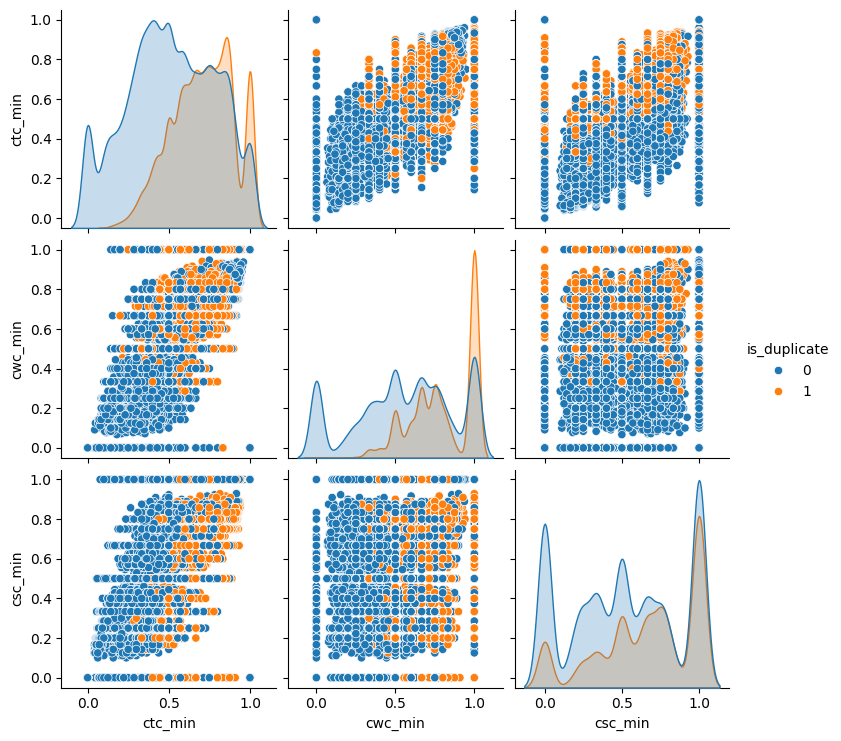

In [23]:
sns.pairplot(new_df[['ctc_min', 'cwc_min', 'csc_min', 'is_duplicate']],hue='is_duplicate')

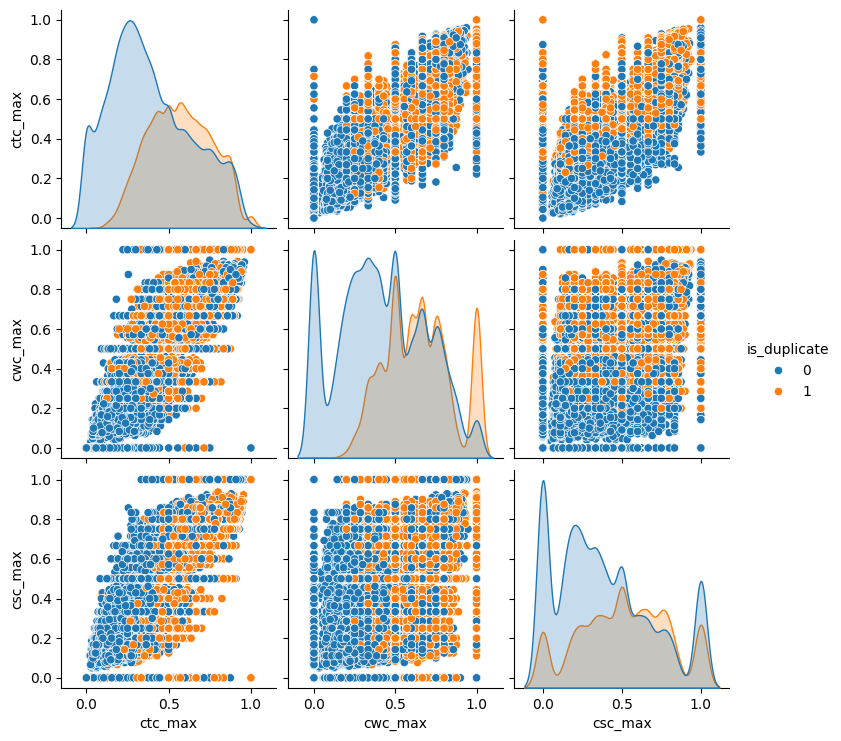

In [24]:
sns.pairplot(new_df[['ctc_max', 'cwc_max', 'csc_max', 'is_duplicate']],hue='is_duplicate')

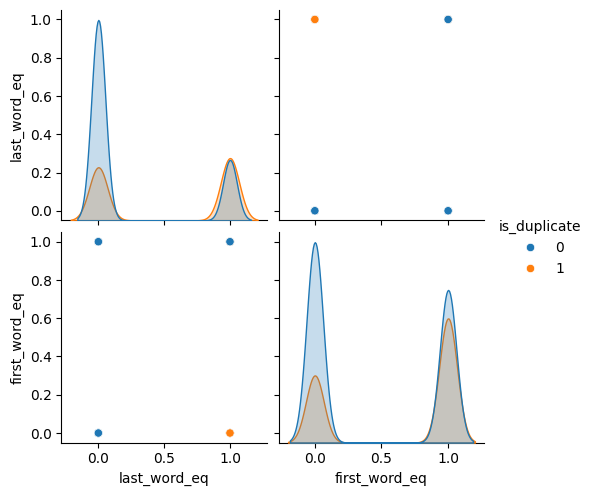

In [25]:
sns.pairplot(new_df[['last_word_eq', 'first_word_eq', 'is_duplicate']],hue='is_duplicate')

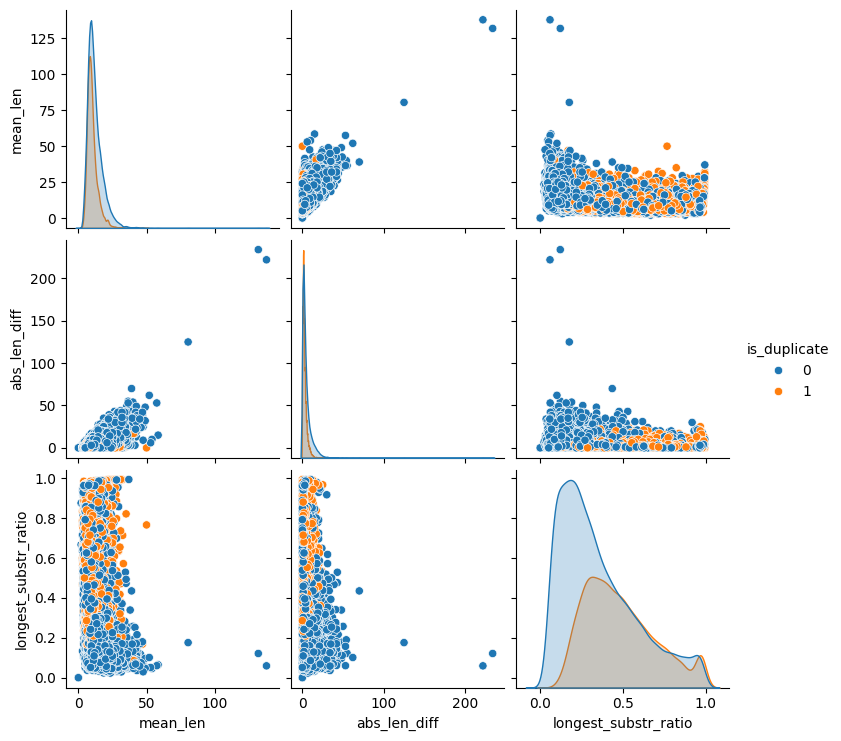

In [26]:
sns.pairplot(new_df[['mean_len', 'abs_len_diff','longest_substr_ratio', 'is_duplicate']],hue='is_duplicate')

In [27]:
new_df.columns

Index(['id', 'qid1', 'qid2', 'question1', 'question2', 'is_duplicate',
       'q1_len', 'q2_len', 'q1_num_words', 'q2_num_words', 'word_common',
       'word_total', 'word_share', 'cwc_min', 'cwc_max', 'csc_min', 'csc_max',
       'ctc_min', 'ctc_max', 'last_word_eq', 'first_word_eq', 'abs_len_diff',
       'mean_len', 'longest_substr_ratio'],
      dtype='object')

In [28]:


from sklearn.preprocessing import MinMaxScaler

X = MinMaxScaler().fit_transform(new_df[['q1_len', 'q2_len', 'q1_num_words', 'q2_num_words', 'word_common', 'word_share','cwc_min', 'cwc_max', 'csc_min', 'csc_max' , 'ctc_min' , 'ctc_max' , 'last_word_eq', 'first_word_eq' , 'abs_len_diff' , 'mean_len'  , 'longest_substr_ratio']])
y = new_df['is_duplicate'].values

In [29]:
ques_df = new_df[['question1','question2']]
ques_df.head()

,question1,question2
398782,what is the best market autom tool for small a...,what is the best market autom tool for small a...
115086,i am poor but i want to invest what should i do,i am quit poor and i want to be veri rich what...
327711,i am from india and live abroad i met a guy fr...,t i e t to thapar univers to thapar univers in...
367788,whi do so mani peopl in the u s hate the south...,my boyfriend doesnt feel guilti when he hurt m...
151235,consequ of bhopal ga tragedi,what wa the reason behind the bhopal ga tragedi


In [30]:
final_df = new_df.drop(columns=['id','qid1','qid2','question1','question2'])
print(final_df.shape)
final_df.head()

(50000, 19)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,cwc_min,cwc_max,csc_min,csc_max,ctc_min,ctc_max,last_word_eq,first_word_eq,abs_len_diff,mean_len,longest_substr_ratio
398782,1,65,65,13,13,13,26,0.50,0.999988,0.999988,0.999980,0.999980,0.999992,0.999992,1.0,1.0,0.0,13.0,0.984848
115086,0,47,54,12,15,7,22,0.32,0.666644,0.399992,0.714276,0.714276,0.583328,0.466664,1.0,1.0,3.0,13.5,0.229167
327711,0,101,102,26,20,3,36,0.08,0.000000,0.000000,0.499992,0.272725,0.149999,0.115384,0.0,0.0,6.0,23.0,0.049020
367788,0,55,133,13,30,0,32,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,17.0,21.5,0.053571
151235,0,28,47,5,9,3,13,0.23,0.749981,0.499992,0.000000,0.000000,0.599988,0.333330,1.0,0.0,4.0,7.0,0.620690


In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

# Merge texts
questions = list(ques_df['question1']) + list(ques_df['question2'])

# Use TfidfVectorizer instead of CountVectorizer
tfidf = TfidfVectorizer(max_features=3000)
q1_arr, q2_arr = np.vsplit(tfidf.fit_transform(questions).toarray(), 2)

In [32]:
temp_df1 = pd.DataFrame(q1_arr, index= ques_df.index)
temp_df2 = pd.DataFrame(q2_arr, index= ques_df.index)
temp_df = pd.concat([temp_df1, temp_df2], axis=1)
temp_df.shape

(50000, 6000)

In [33]:
final_df = pd.concat([final_df, temp_df], axis=1)
print(final_df.shape)
final_df.head()

(50000, 6019)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,cwc_min,cwc_max,...,2990,2991,2992,2993,2994,2995,2996,2997,2998,2999
398782,1,65,65,13,13,13,26,0.50,0.999988,0.999988,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
115086,0,47,54,12,15,7,22,0.32,0.666644,0.399992,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
327711,0,101,102,26,20,3,36,0.08,0.000000,0.000000,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
367788,0,55,133,13,30,0,32,0.00,0.000000,0.000000,...,0.167743,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
151235,0,28,47,5,9,3,13,0.23,0.749981,0.499992,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [34]:
# Convert all column names to strings
final_df.columns = final_df.columns.astype(str)

from sklearn.decomposition import PCA

# Define the number of principal components
n_components = 500

# Initialize PCA
pca = PCA(n_components=n_components)

# Apply PCA to reduce dimensionality
final_df_pca = pca.fit_transform(final_df.iloc[:, 1:])

# Check the new shape of the transformed data
print(final_df_pca.shape)


(50000, 500)


In [35]:
final_df

,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,cwc_min,cwc_max,...,2990,2991,2992,2993,2994,2995,2996,2997,2998,2999
398782,1,65,65,13,13,13,26,0.50,0.999988,0.999988,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
115086,0,47,54,12,15,7,22,0.32,0.666644,0.399992,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
327711,0,101,102,26,20,3,36,0.08,0.000000,0.000000,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
367788,0,55,133,13,30,0,32,0.00,0.000000,0.000000,...,0.167743,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
151235,0,28,47,5,9,3,13,0.23,0.749981,0.499992,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
362916,0,51,23,10,5,3,15,0.20,0.333322,0.249994,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
292183,0,28,45,7,11,4,17,0.24,0.749981,0.599988,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
360529,0,23,25,5,5,4,10,0.40,0.749981,0.749981,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
327759,0,75,47,14,10,7,24,0.29,0.499992,0.428565,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [36]:
final_df.iloc[:,0].values

array([1, 0, 0, ..., 0, 0, 0], dtype=int64)

In [37]:
final_df_pca.shape

(50000, 500)

In [38]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(final_df_pca,final_df.iloc[:,0].values,test_size=0.2,random_state=1)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
#rf = RandomForestClassifier()
#rf.fit(X_train,y_train)
#y_pred = rf.predict(X_test)
#accuracy_score(y_test,y_pred)
# for random forest model
#confusion_matrix(y_test,y_pred)

In [40]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
xgb = XGBClassifier()
xgb.fit(X_train,y_train)
y_pred1 = xgb.predict(X_test)
accuracy_score(y_test,y_pred1)

0.7751

In [41]:
from sklearn.metrics import confusion_matrix

In [43]:
# for xgboost model
confusion_matrix(y_test,y_pred1)

array([[5322,  963],
       [1286, 2429]], dtype=int64)

In [ ]:
import pickle

pickle.dump(xgb,open('model.pkl','wb'))
pickle.dump(tfidf,open('cv.pkl','wb'))
pickle.dump(pca,open('pca.pkl','wb'))
